# Original descent chain on empirical AR(3) widths

The selector is unchanged. This experiment implements the LP tangent fitting procedure in Eq. (1.7) and Algorithm 2 (pp. 8–9) of [the supplied preview](/Users/iljasukhanov/Downloads/elbow_point_selection_preview.pdf), on the same 50 saved AR(3) series with T=2000. All dimensions use response times t=10,...,2000. The three starts are the previous direction padded on the right, padded on the left, and the first coordinate axis. The original fitted curves remain saved separately.

Raw widths and the log transformation of Remark 1.2.16 (p. 7) are reported separately. Caps 5 and 8 truncate the same K=10 curve. K=5 is an oracle-bound diagnostic, not an automatically selected cap. No statistical stabilizer or smoothing is used.

The [research note](/Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/ar3_descent_chain_empirical_note.md) gives the proofs of the numerical failure diagnostic, the limitations of width consistency, and a weaker sufficient condition for consistency of the unchanged selector. No thesis source has been edited.


In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
PROJECT_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                    if (root / "Code/Code_AR_processes/ar3_descent_chain_lp.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Code.Code_AR_processes.ar3_descent_chain_lp import run_experiment, make_plots, DATA_DIR, IMAGE_DIR


In [2]:
data_dir = run_experiment()
widths = pd.read_csv(DATA_DIR / "width_curves.csv", float_precision="round_trip")
make_plots(widths)



LP descent-chain results:
 cap transform  correct  under  over  total
   5  identity       42      8     0     50
   5       log       46      4     0     50
   8  identity       39     11     0     50
   8       log       41      9     0     50
  10  identity       36     13     1     50
  10       log       40      9     1     50
{
  "curves": 50,
  "monotonicity_violations_above_1e-12": 0,
  "maximum_lp_gap_global_k2_to_k4": 0.9590479484461802,
  "k4_global_audit_matches_within_1e-8": 49,
  "k4_widths_above_known_feasible_direction_by_1e-8": 0,
  "total_lp_solves": 3716,
  "starts_hitting_iteration_limit": 0,
  "maximum_saved_direction_width_reconstruction_error": 0.0,
  "maximum_saved_direction_unit_norm_error": 3.3306690738754696e-16
}


## Selection results

These are paired descriptive results on the existing 50 processes. The previous padded subgradient fit gave 19/50 correct selections at K=10. The new LP fit gives 36/50 on raw widths and 40/50 on log-widths. They are local fits, not globally certified minima in all dimensions. See [previous results](/Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_order_selection_warm_starts/summary.csv) and the saved summaries below.


correct  under  over  total
cap transform                             
5   identity        42      8     0     50
    log             46      4     0     50
8   identity        39     11     0     50
    log             41      9     0     50
10  identity        36     13     1     50
    log             40      9     1     50

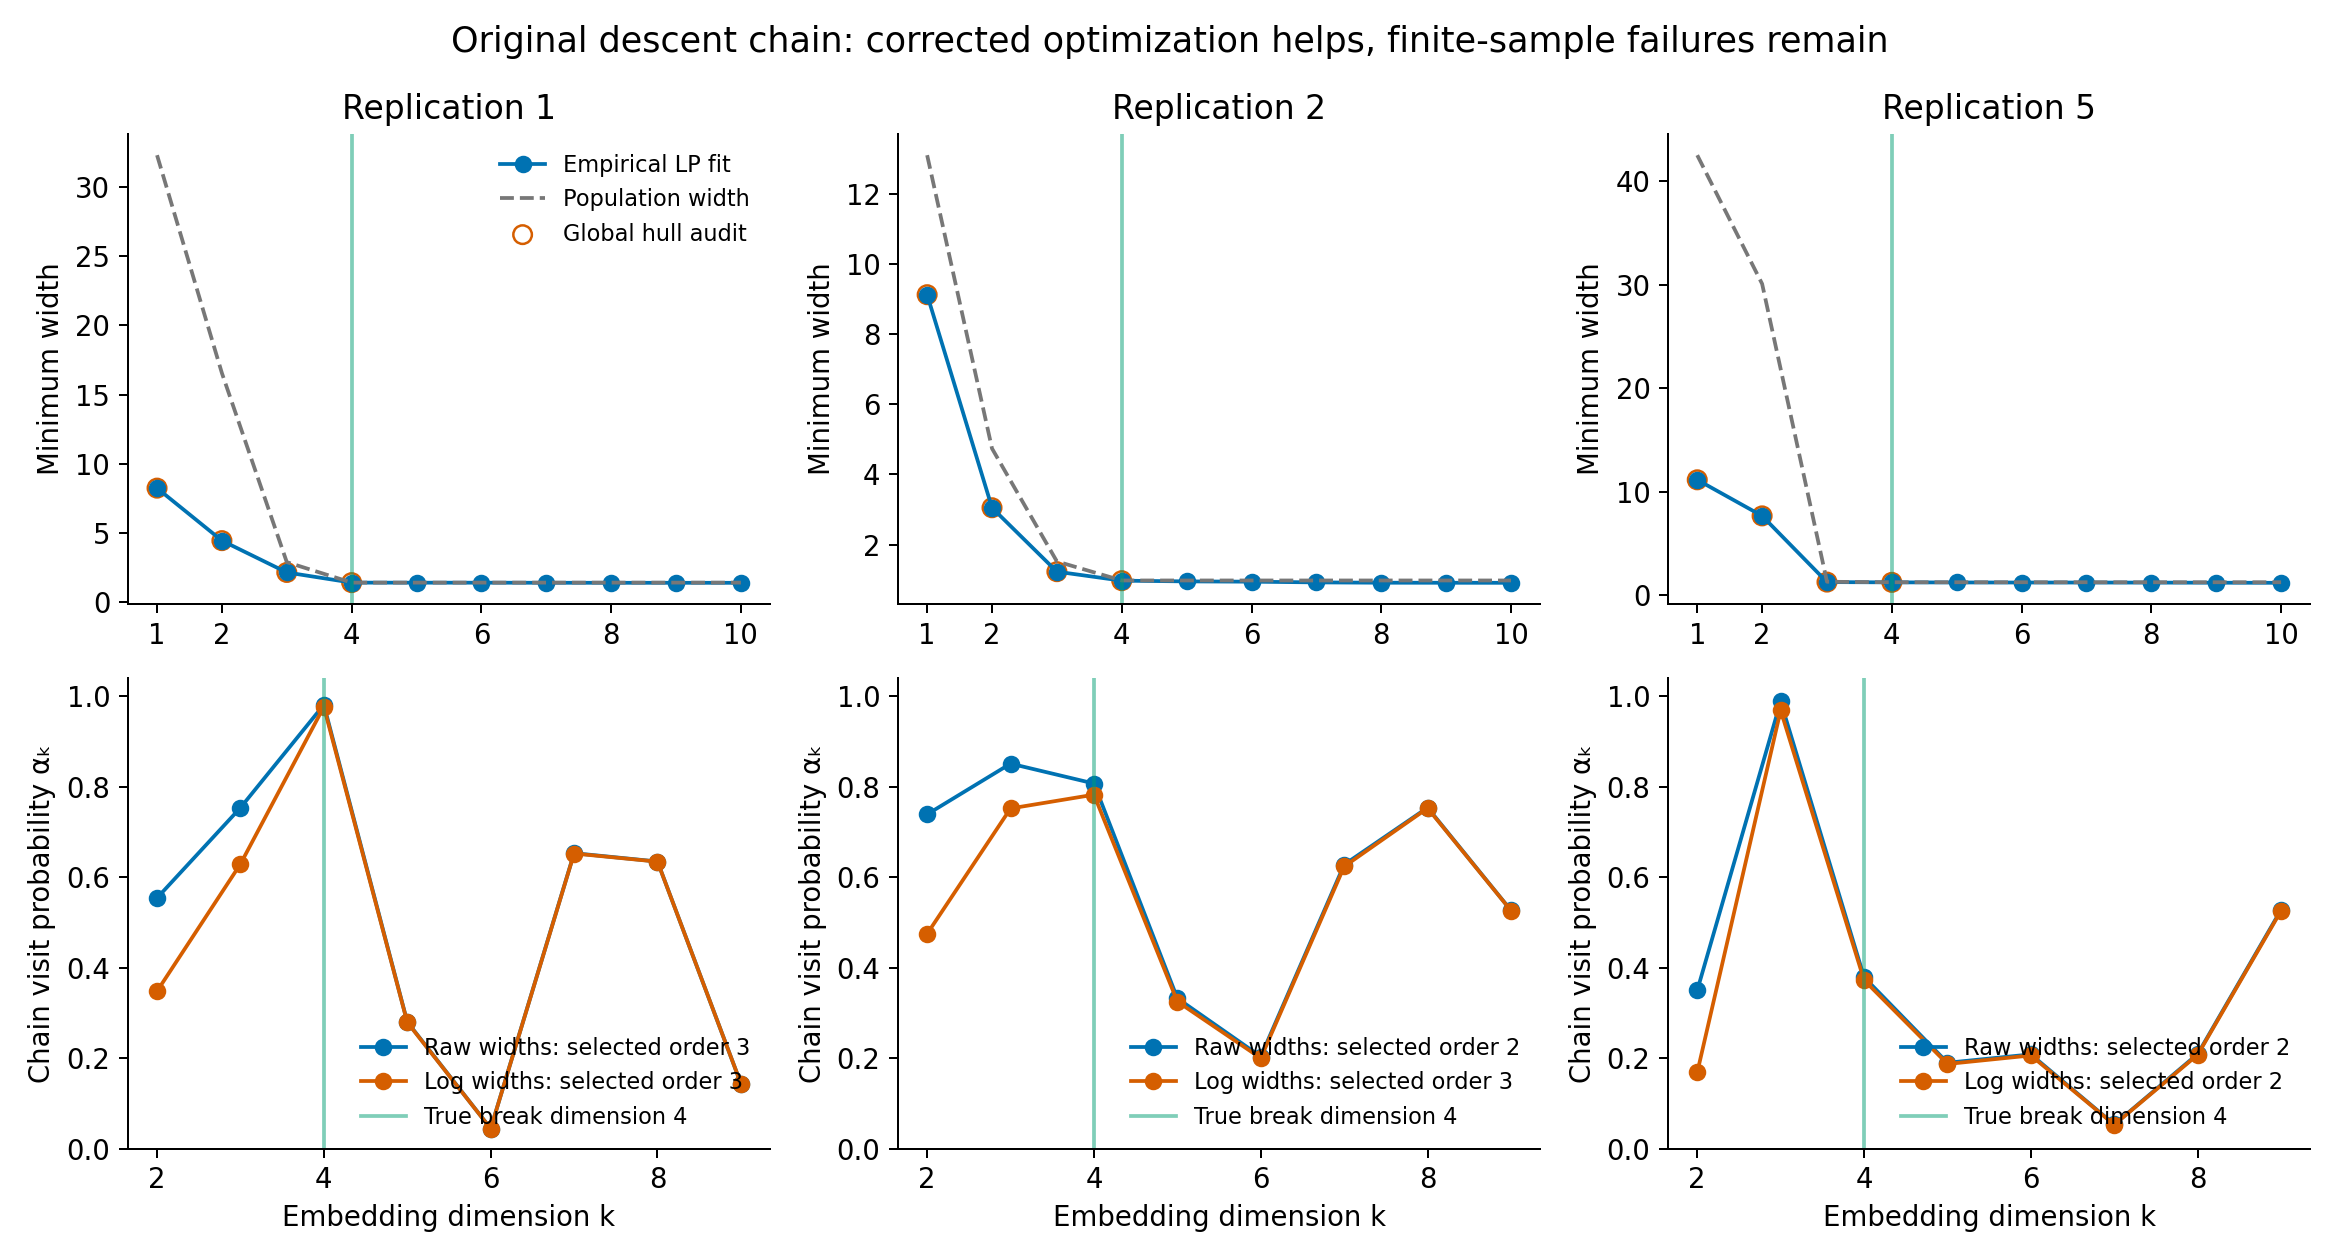

In [3]:
summary = pd.read_csv(DATA_DIR / "summary.csv")
display(summary.set_index(["cap", "transform"]))
display(Image(filename=str(IMAGE_DIR / "lp_descent_chain_examples.png")))


## Global prefix audits and failures that a better tail optimizer cannot fix

Dimensions 1–4 are audited globally using facet distances of the convex hull of the difference body. This is a floating-point geometric calculation; the argument and numerical limits are in the research note. Replacing the fitted prefix by the global audit leaves the K=10 selection counts unchanged.

An earlier candidate's score has the form A/(a-b), while the true candidate's score is B/(c-b), with a≥c>b. If A(c-b)−B(a-b)>0 at a feasible terminal upper bound b, the earlier candidate also wins for every smaller terminal width. This supplies a deterministic diagnosis for 13 raw-width cases and 9 log-width cases, conditional on accurate global prefix audits. It does not depend on whether dimensions 5–10 reached global minima.


In [4]:
certificates = pd.read_csv(DATA_DIR / "earlier_bend_certificates.csv")
display(certificates.groupby("transform")["earlier_bend_wins_for_all_smaller_terminal_widths"].sum().to_frame("earlier-bend failures"))
replaced = pd.read_csv(DATA_DIR / "global_prefix_selections.csv")
display(replaced.groupby("transform").selected_order_after_global_prefix_replacement.agg(
    correct=lambda q: int((q == 3).sum()), under=lambda q: int((q < 3).sum()), over=lambda q: int((q > 3).sum())))
display(certificates[certificates.replication == 5])


,earlier-bend failures
transform,
identity,13
log,9


,correct,under,over
transform,,,
identity,36,13,1
log,40,9,1


,replication,transform,terminal_upper_width,earlier_order,earlier_score_at_terminal_upper,true_score_at_terminal_upper,cross_product_margin,earlier_drop,true_drop,earlier_bend_wins_for_all_smaller_terminal_widths
8,5,identity,1.219242,2,90.775609,0.611552,0.277740,6.395788,0.026737,True
9,5,log,0.198229,2,31.771757,0.594632,0.061707,1.784925,0.020949,True


## Verification and theory limits

The saved unit directions are checked against the physical ranges of the common-time point clouds. All 50 curves are monotone. Theorem 1.2.14 of the preview (p. 7) concerns exact empirical minima and needs plateau-fluctuation condition (N) for a general cap. These local LP results do not prove that condition or control their own error relative to global minima in dimensions 5–10.

Every displayed plot has a PDF copy in `outputs/pdfs/ar3_descent_chain_lp/`. All 50 fitted width curves, 500 unit directions, global prefix audits, original chain scores, selections, and deterministic failure diagnostics are saved under `outputs/csv/ar3_descent_chain_lp/`.


In [5]:
verification = json.loads((DATA_DIR / "verification.json").read_text())
print(json.dumps(verification, indent=2))
assert verification["monotonicity_violations_above_1e-12"] == 0
assert verification["maximum_saved_direction_width_reconstruction_error"] < 1e-10
assert verification["maximum_saved_direction_unit_norm_error"] < 1e-12


{
  "curves": 50,
  "monotonicity_violations_above_1e-12": 0,
  "maximum_lp_gap_global_k2_to_k4": 0.9590479484461802,
  "k4_global_audit_matches_within_1e-8": 49,
  "k4_widths_above_known_feasible_direction_by_1e-8": 0,
  "total_lp_solves": 3716,
  "starts_hitting_iteration_limit": 0,
  "maximum_saved_direction_width_reconstruction_error": 0.0,
  "maximum_saved_direction_unit_norm_error": 3.3306690738754696e-16
}
